# Прогнозирование прогрессирования диабета
**Python · Machine Learning · Регрессия · Учебный проект**

Воспроизводимое сравнение базового прогноза, дерева решений и линейной регрессии на данных `sklearn.datasets.load_diabetes`. Развитие исходной лабораторной работы: добавлены кросс-валидация, подбор гиперпараметров, визуальная диагностика и ограничения.

> Прогнозируется **количественный показатель прогрессирования заболевания через год**, а не наличие или вероятность диабета. Это учебный эксперимент, **не медицинское приложение**.

## Краткий итог
- **442 наблюдения**, **10 признаков**, из них **89** отложены на тест.
- Линейная регрессия — лучшая по **CV MAE = 44,86** на обучающей части.
- Финальная тестовая оценка линейной регрессии: **MAE = 44,66; R² = 0,527**.
- Подбор параметров дерева уменьшил его тестовую MAE с **60,29 до 48,11**.

Числа ниже воспроизводятся при фиксированном `random_state=5`. Победитель определяется по обучающей CV, а не по тестовой выборке.

## 1. Задача и методика

**Модели:** `DummyRegressor` (среднее), исходное `DecisionTreeRegressor(min_samples_leaf=3)`, дерево с подбором гиперпараметров, `LinearRegression` в `Pipeline` со `StandardScaler`.

**Оценка:** разделение 80/20; выбор модели по **5-fold KFold CV** только на обучающих данных; для дерева с поиском параметров — **вложенная 3-fold CV внутри каждого внешнего фолда**. Финальный тест не используется для выбора модели.

**Метрики:** MAE — средняя абсолютная ошибка, меньше лучше; R² — коэффициент детерминации, больше лучше. MAE измеряется в единицах целевого показателя, а не в процентах или единицах глюкозы.

## 2. Импорт и параметры

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, r2_score

SEED = 5
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.dpi':110,
                     'axes.spines.top':False,'axes.spines.right':False})

## 3. Данные и контроль качества

`scaled=False` позволяет избежать стандартизации **до разделения на обучение и тест**. Масштабирование линейной модели выполняется только внутри `Pipeline` и соответствующего CV-фолда.

In [2]:
data = load_diabetes(as_frame=True, scaled=False)
X, y = data.data, data.target
assert X.shape == (442, 10) and len(y) == 442
assert not X.isna().any().any() and not y.isna().any()
print('Размер:', X.shape, '| Пропусков:', int(X.isna().sum().sum() + y.isna().sum()))
print('Признаки:', ', '.join(X.columns))
pd.concat([X, y.rename('target')], axis=1).head()

Размер: (442, 10) | Пропусков: 0
Признаки: age, sex, bmi, bp, s1, s2, s3, s4, s5, s6


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'Обучение: {len(X_train)}; тест: {len(X_test)}')

Обучение: 353; тест: 89


## 4. Модели и кросс-валидация

**Критически важно:** `GridSearchCV` внутри внешней CV предотвращает оптимистичную оценку результата дерева, которое подбирает гиперпараметры. Все модели сравниваются на одних и тех же внешних фолдах.

In [4]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
models = {
    'Прогноз среднего': DummyRegressor(strategy='mean'),
    'Дерево (исходное)': DecisionTreeRegressor(min_samples_leaf=3, random_state=SEED),
    'Дерево (подбор CV)': GridSearchCV(
        DecisionTreeRegressor(random_state=SEED),
        {'max_depth': [2, 3, 4, 5, None], 'min_samples_leaf': [3, 5, 10, 15]},
        scoring='neg_mean_absolute_error', cv=inner_cv, n_jobs=1),
    'Линейная регрессия': Pipeline([
        ('scaler', StandardScaler()), ('regressor', LinearRegression())]),
}

In [5]:
cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(estimator, X_train, y_train, cv=outer_cv,
        scoring={'mae': 'neg_mean_absolute_error', 'r2': 'r2'},
        return_train_score=True, n_jobs=1)
    cv_rows.append({
        'Модель': name,
        'CV MAE': -scores['test_mae'].mean(),
        'CV MAE SD': scores['test_mae'].std(),
        'CV R²': scores['test_r2'].mean(),
        'CV MAE обучение': -scores['train_mae'].mean(),
    })
cv_results = pd.DataFrame(cv_rows).sort_values('CV MAE').reset_index(drop=True)
cv_results.round(3)

,Модель,CV MAE,CV MAE SD,CV R²,CV MAE обучение
0,Линейная регрессия,44.859,3.318,0.458,42.922
1,Дерево (подбор CV),51.117,4.179,0.292,41.878
2,Дерево (исходное),59.886,2.951,-0.075,19.926
3,Прогноз среднего,65.323,5.126,-0.023,65.084


**CV MAE ± SD по пяти внешним фолдам.** SD отражает разброс по фолдам, а не доверительный интервал прогноза.

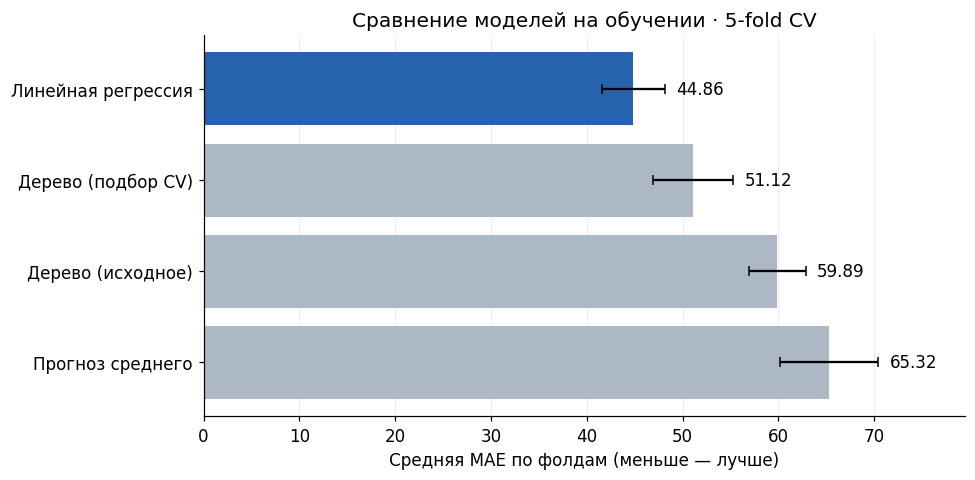

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
vals = cv_results['CV MAE'].to_numpy()
order = np.arange(len(vals))
bars = ax.barh(order, vals, xerr=cv_results['CV MAE SD'], capsize=3,
    color=['#2762af'] + ['#adb8c6']*(len(vals)-1))
ax.set_yticks(order, cv_results['Модель'])
ax.invert_yaxis()
ax.set_xlim(0, max(vals + cv_results['CV MAE SD'].to_numpy()) + 9)
ax.set_xlabel('Средняя MAE по фолдам (меньше — лучше)')
ax.set_title('Сравнение моделей на обучении · 5-fold CV')
ax.grid(axis='x', alpha=0.2); ax.set_axisbelow(True)
for bar, value, sd in zip(bars, vals, cv_results['CV MAE SD']):
    ax.text(value+sd+1.2, bar.get_y()+bar.get_height()/2,
            f'{value:.2f}', va='center')
fig.tight_layout()
fig.savefig(FIGURES/'cv_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Финальная проверка на отложенной выборке

**Выбор сделан:** название итоговой модели определяется минимальной CV MAE. После обучения на всех 353 тренировочных наблюдениях сравним тестовые ошибки. На основании результатов теста **не меняем победителя**.

In [7]:
best_name = cv_results.iloc[0]['Модель']
test_rows, fitted = [], {}
for name, estimator in models.items():
    fitted[name] = estimator.fit(X_train, y_train)
    pred_train = estimator.predict(X_train)
    pred_test = estimator.predict(X_test)
    test_rows.append({
        'Модель': name,
        'MAE обучение': mean_absolute_error(y_train, pred_train),
        'MAE тест': mean_absolute_error(y_test, pred_test),
        'R² обучение': r2_score(y_train, pred_train),
        'R² тест': r2_score(y_test, pred_test),
    })
test_results = pd.DataFrame(test_rows).sort_values('MAE тест')
print('Итоговый выбор по CV:', best_name)
print('Параметры настроенного дерева:', fitted['Дерево (подбор CV)'].best_params_)
test_results.round(3)

Итоговый выбор по CV: Линейная регрессия
Параметры настроенного дерева: {'max_depth': 5, 'min_samples_leaf': 15}


,Модель,MAE обучение,MAE тест,R² обучение,R² тест
3,Линейная регрессия,43.133,44.660,0.512,0.527
2,Дерево (подбор CV),38.911,48.107,0.572,0.393
1,Дерево (исходное),18.120,60.292,0.891,0.043
0,Прогноз среднего,65.106,67.608,0.000,-0.008


### Анализ переобучения дерева

У исходного дерева большая разница между ошибкой на обучении и тесте. Подбор глубины и размера листа уменьшает этот разрыв, хотя и не делает дерево лучшей моделью.

In [8]:
by_model = test_results.set_index('Модель')
for name in ['Дерево (исходное)', 'Дерево (подбор CV)']:
    row = by_model.loc[name]
    print(f"{name}: MAE обучение = {row['MAE обучение']:.2f}; "
          f"MAE тест = {row['MAE тест']:.2f}; R² тест = {row['R² тест']:.3f}")

Дерево (исходное): MAE обучение = 18.12; MAE тест = 60.29; R² тест = 0.043
Дерево (подбор CV): MAE обучение = 38.91; MAE тест = 48.11; R² тест = 0.393


### Фрагмент исходного дерева решений (первые два уровня)

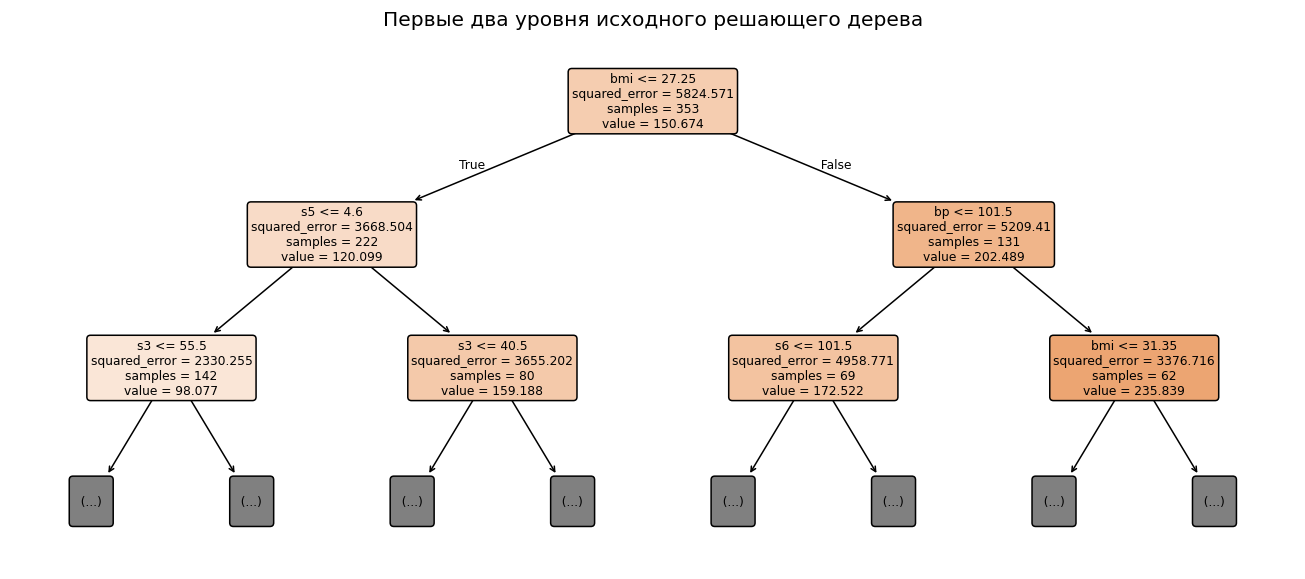

In [9]:
fig, ax = plt.subplots(figsize=(12, 5.4))
plot_tree(fitted['Дерево (исходное)'], feature_names=list(X.columns),
          max_depth=2, fontsize=8, filled=True, rounded=True, ax=ax)
ax.set_title('Первые два уровня исходного решающего дерева')
fig.tight_layout()
fig.savefig(FIGURES/'decision_tree.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Визуальная диагностика итоговой модели

Точки на графике — **89 тестовых наблюдений**. Диагональная линия соответствует идеальному прогнозу. Остаток определяется как **факт − прогноз**.

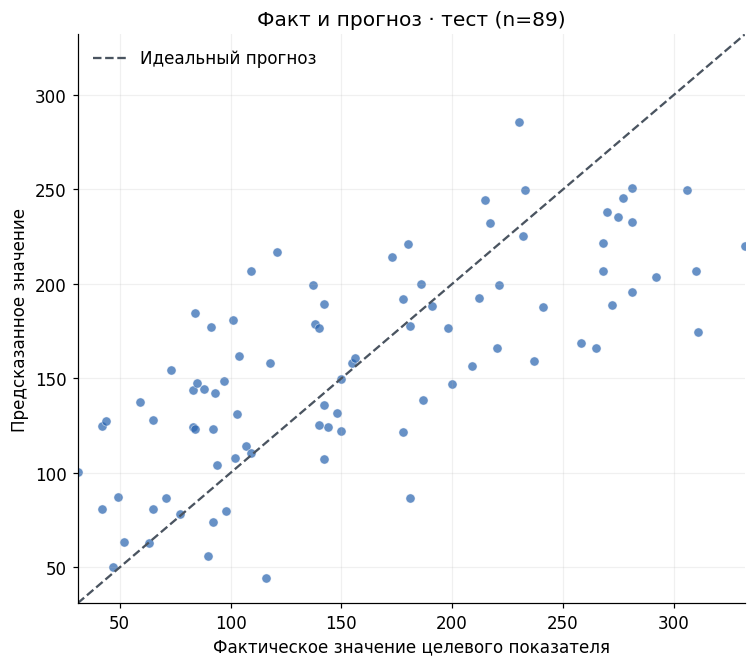

In [10]:
predictions = fitted[best_name].predict(X_test)
residuals = y_test.to_numpy() - np.asarray(predictions)

fig, ax = plt.subplots(figsize=(7, 6.2))
ax.scatter(y_test, predictions, s=36, alpha=0.7, color='#2762af',
           edgecolors='white', linewidth=0.4)
low = min(float(y_test.min()), float(np.min(predictions)))
high = max(float(y_test.max()), float(np.max(predictions)))
diagonal = np.linspace(low, high, 100)
ax.plot(diagonal, diagonal, '--', color='#4a5460', label='Идеальный прогноз')
ax.set(xlim=(low, high), ylim=(low, high),
       xlabel='Фактическое значение целевого показателя',
       ylabel='Предсказанное значение',
       title=f'Факт и прогноз · тест (n={len(y_test)})')
ax.legend(frameon=False); ax.grid(alpha=0.18)
fig.tight_layout()
fig.savefig(FIGURES/'actual_vs_predicted.png', dpi=160, bbox_inches='tight')
plt.show()

### Остатки: есть ли систематические ошибки?

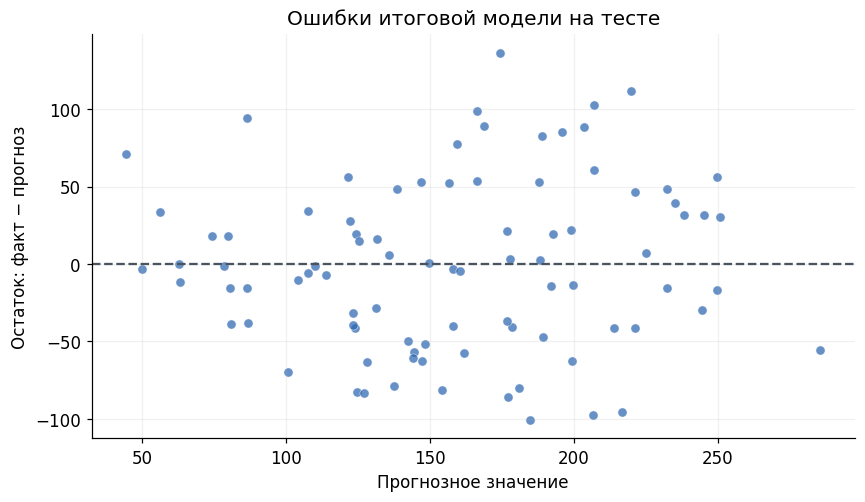

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.7))
ax.scatter(predictions, residuals, s=36, alpha=0.7,
           color='#2762af', edgecolors='white', linewidth=0.4)
ax.axhline(0, linestyle='--', color='#4a5460')
ax.set(xlabel='Прогнозное значение', ylabel='Остаток: факт − прогноз',
       title='Ошибки итоговой модели на тесте')
ax.grid(alpha=0.18)
fig.tight_layout()
fig.savefig(FIGURES/'residuals.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Выводы и ограничения

1. **Линейная регрессия** выбрана по минимальной CV MAE (**44,86**); на независимом тесте получила **MAE 44,66; R² 0,527**.
2. Базовый прогноз среднего получил **MAE 67,61; R² −0,008** на тесте. Линейная регрессия использует информацию из признаков и превосходит базовый вариант.
3. Исходное дерево имеет **MAE 18,12 на обучении против 60,29 на тесте** — признак переобучения. С подбором параметров его тестовая MAE снижается до **48,11**, но остаётся выше линейной модели.
4. **Ограничения:** небольшая учебная выборка; одно фиксированное финальное разбиение; нет внешней проверки качества. SD CV — не доверительный интервал. Результаты не предназначены для диагностики, лечения или иных клинических решений.

**Идеи развития:** повторная CV при разных случайных разбиениях; модели `Ridge`/`Lasso`; интерпретация ошибок и коэффициентов с осторожностью относительно медицинского смысла.